# Exercises week 43: reading a classifier — the confusion matrix, the ROC curve and the threshold

## Collaborated with Simon Berg

**FYS-STK3155/4155 Applied Data Analysis and Machine Learning**

**October 19–23, 2026**

**Deadline: Friday October 23 at midnight** (one notebook per group, in
Canvas).

## Aims of this week's exercises

Project 2 asks you to train classifiers — logistic regression as the
baseline and a neural network with hidden layers — and then to *say what
they do*: the confusion matrix on the test set, with its interpretation.
This week you build the tools for that, implementing them yourself from the
definitions and checking them against `scikit-learn`:

- the confusion matrix and the quantities read off its four counts —
  accuracy, precision, recall, $F_1$ (Section 5.12, Eqs. 5.67–5.70);
- the ROC curve and the area under it, the AUC, and why they measure
  something a single threshold cannot;
- (optional) the $K\times K$ confusion matrix of a multiclass classifier and
  how to read a $2\times2$ matrix off it.

The Monday lecture went through what every one of these measures *means* on
a worked screening example and then applied them to "is it a five?" on the
full MNIST set (`week43monday.pdf`, `week43monday.ipynb`); the Tuesday session
goes through the worked example in detail and then writes the same code on
the small digits set (`week43tuesday.ipynb`). The classifiers can be your
own Project 2 code (recommended: this is the code you will report on) or
`scikit-learn`'s `LogisticRegression` and `MLPClassifier`.

There is no validation set and no cross-validation in this week's
exercises: how to cross-validate your Project 2 network is the topic of next
week's Tuesday session and exercises.

**Reading:** Sections 5.12–5.13 of the lecture notes; Eq. (2.24) for the
standard error of a proportion. Hastie, Tibshirani and Friedman, Section
9.2.5; Raschka et al., Chapter 6 ("Looking at different performance
evaluation metrics").

In [144]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import metrics as skm
np.random.seed(2026)
import jax

# GENERAL COMMENTS: 
Note that a lot of the code presented in this weekly exercise are taken from Morten's lecture notes, and notebooks presented in the weekly material.

## Exercise 1: your own confusion matrix, ROC curve and AUC, checked

Implement the following functions from their definitions. Labels are in
$\{0,1\}$ with $1$ the positive class; `scores` are the output probabilities
(or any monotone score) of a classifier.

**a)** `confusion_matrix(y_true, y_pred)` returning the four counts
`tp, fn, fp, tn` of Eq. (5.67), and from them the accuracy, precision,
recall and $F_1$ of Eqs. (5.68)–(5.70) (handle the cases where a
denominator is zero).

**b)** `roc_curve(y_true, scores)` returning the false positive rates, true
positive rates and thresholds for every distinct score, from **one sorted
pass**: sort by decreasing score and walk down the list — every sample
flagged adds one to TP if it is a positive and one to FP if it is a
negative; then `auc_trapezoid(fpr, tpr)` for the area.

**c)** `roc_auc(y_true, scores)` by the rank formula of the lecture,
$\mathrm{AUC}=\bigl(\sum_{i\in\mathrm{pos}}R_i-\tfrac12 n_+(n_++1)\bigr)/(n_+n_-)$,
with average ranks for tied scores (`np.unique` with `return_inverse` and
`return_counts`, or `scipy.stats.rankdata`). Explain in one sentence why
this is the probability that a random positive outscores a random negative.

**d)** Test everything on the small example below against `sklearn.metrics`
(`confusion_matrix`, `precision_score`, `recall_score`, `f1_score`,
`roc_curve` with `drop_intermediate=False`, `roc_auc_score`). Mind the
layout of `sklearn.metrics.confusion_matrix`: rows true $0/1$, columns
predicted $0/1$, so `[[TN, FP], [FN, TP]]`. The example has tied scores on
purpose: the three AUCs must still agree.

In [145]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn

def classification_report(y_true, y_pred):
    # accuracy, precision, recall and F1 from the four counts
    """Every scalar summary is a function of the four counts: Eqs. (5.68)-(5.70) and a few more."""
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)

def roc_curve(y_true, scores):
    """False and true positive rates as the threshold sweeps down through every distinct score.

    Sorting the scores once gives every point of the curve in O(n log n):
    walking down the sorted list, each sample flagged positive adds one to
    TP (if it is a positive) or to FP (if it is a negative).
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds

def auc_trapezoid(fpr, tpr):
    """The area under the ROC curve by the trapezoidal rule."""
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))

def roc_auc(y_true, scores):
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))

# a small test: 20 samples, 6 positives, scores rounded to one decimal so that there are ties
rng = np.random.default_rng(2)
y_small = np.array([1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0])
s_small = np.round(np.clip(0.35 * y_small + rng.normal(0.3, 0.2, 20), 0, 1), 1)
print(confusion_matrix(y_small, s_small > 0.5), skm.confusion_matrix(y_small, s_small > 0.5))
print(roc_auc(y_small, s_small), auc_trapezoid(*roc_curve(y_small, s_small)[:2]), skm.roc_auc_score(y_small, s_small))

(5, 1, 1, 13) [[13  1]
 [ 1  5]]
0.8571428571428571 0.8571428571428572 0.8571428571428571


**The same with `scikit-learn`.** Once your functions agree with the
library, this is the template you can use in Project 2 for the test set
(`y_test` the true labels, `p_test` the output probabilities of your
classifier, `y_pred = p_test > 0.5` the decisions):

[[13  1]
 [ 1  5]]
accuracy 0.9000  precision 0.8333  recall 0.8333  F1 0.8333
              precision    recall  f1-score   support

    negative       0.93      0.93      0.93        14
    positive       0.83      0.83      0.83         6

    accuracy                           0.90        20
   macro avg       0.88      0.88      0.88        20
weighted avg       0.90      0.90      0.90        20

AUC 0.8571


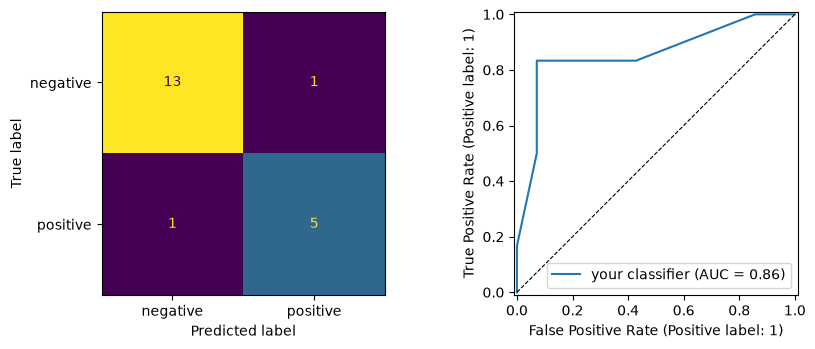

In [146]:
from sklearn.metrics import (confusion_matrix as sk_confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report as sk_classification_report,
                             roc_curve as sk_roc_curve, roc_auc_score, RocCurveDisplay)

y_test, p_test = y_small, s_small          # replace by your test labels and output probabilities
y_pred = p_test > 0.5

cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]

print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar = False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

## Exercise 2: MNIST, one digit against the rest

This is the Monday lecture's example on data of your choosing, with your
Project 2 code. Use the full MNIST set as described in Project 2 (the file
`mnist.npz`, 60 000 training and 10 000 test images, flattened and scaled to
$[0,1]$); if your laptop is slow, train on a subset of the training images
but evaluate on the full test set.

**a)** Pick a digit $d$ (the lecture used $5$; choose a different one) and
set $y=1$ for the images of $d$. Report the prevalence of $d$ in the test set
and the accuracy of the majority rule ("never $d$") — the number every
accuracy below must be compared with.

In [147]:
	
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)     # double precision, so that gradient checks agree to ~1e-15
import jax.numpy as jnp

np.random.default_rng(2026)

Generator(PCG64) at 0x11F79C3C0

In [ ]:
# your Project 2 network (or the week-41 code: create_layers, feed_forward, backpropagation, train, predict)

def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))


def ReLU(z):
    return jnp.where(z > 0, z, 0.0)

def leaky_ReLU(z, alpha = 0.01):
    return jnp.where(z > 0, z, alpha*z)

def softmax(z):
    """Compute softmax values for each set of scores in the rows of the matrix z.
    Used with batched input data: one row of scores per sample."""
    e_z = jnp.exp(z - jnp.max(z, axis=1, keepdims=False))
    return e_z / jnp.sum(e_z, axis=1, keepdims=True)

def create_layers_batch(network_input_size, layer_output_sizes):
    layers = []
    i_size = network_input_size
    for layer_output_size in layer_output_sizes:
        W = rng.normal(0, 1/np.sqrt(i_size), (i_size, layer_output_size))
        # print(np.shape(W))
        b = np.zeros(layer_output_size) + 0.01
        layers.append((W, b))

        i_size = layer_output_size
    return layers

def feed_forward_batch(inputs, layers, activation_funcs):
    """
    LLM tag: Gave ChatGPT some of my functions, as there were some issues with the dictionary used for the activation functions.
    The LLM helped debug some lines. However, the final solution was to hardcode the sigmoid as the activation function, as this is the one
    we wanted to use throughout the code. 
    """
    a = inputs
    activations = [inputs]
    zs = []
    # print(layers)
    # print(activation_funcs)
    for (W, b), activation_func in zip(layers, activation_funcs):
        z = a @ W + b
        zs.append(z)
        # a = activation_func(z)
        #a = ACTIVATIONS[activation_func](z)
        a = sigmoid(z)
        activations.append(a)
    zs = zs[0]
    # print("zs shape", zs)
    return zs, activations



def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    return feed_forward_batch(X, layers, hidden_activation)[1][-1]

# hidden activations: (f, f')
ACTIVATIONS = {"sigmoid": (sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))),
               "tanh": (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
               "relu": (ReLU, lambda z: (z > 0).astype(float)),
               "identity": (lambda z: z, lambda z: np.ones_like(z))}

def cost(X, Y, layers, hidden_activation="sigmoid", head="mse"):
    """
    LLM tag: AI was used here to help me debug some problems with inhomogenous shapes. 
    The problem was that I had mixed this "cost" function and the "jax_cost" function, and when the LLM
    reminded me to not mix them (e.g. by renaming the jax_cost function), my code worked. 
    """
    out = predict(X, layers, hidden_activation, head)
    if head == "mse":
        return 0.5 * np.sum((out - Y) ** 2) / len(X)
    p = np.clip(out, 1e-12, 1 - 1e-12)
    if head == "binary":
        return -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    return -np.mean(np.sum(Y * np.log(p), axis=1))


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse"):
    # The four equations, for all samples at once. Returns [(dW, db), ...] with the shapes of [(W, b), ...].
    act_function, fp = ACTIVATIONS[hidden_activation]

    activation_func = ACTIVATIONS[hidden_activation][0]
    activation_funcs = [activation_func] * len(layers)
    z, a = feed_forward_batch(X, layers, activation_funcs)
    
    delta = (a[-1] - Y) / len(X)                         # output layer: prediction minus target
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        grads[l] = (a[l].T @ delta, np.sum(delta, axis=0))   # dC/dW = A^T Delta,  dC/db = sum of rows
        if l > 0:
            W = layers[l][0]
            delta = (delta @ W.T) * fp(z[l - 1])         # one layer back
    return grads

def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, rng=None, X_test=None, y_test=None):
    # Plain gradient descent on minibatches (batch_size=None: all data in every step).
    rng = np.random.default_rng(2026) if rng is None else rng
    n = len(X)
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head))
        if X_test is not None:
            pred = np.argmax(predict(X_test, layers, hidden_activation, head), axis=1)
            history["test_accuracy"].append(np.mean(pred == y_test))
    return layers, history


def one_hot(y, n_classes):
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y

"""
BLUE = "#2a8fb3"
GREEN = "#2ab37a"
RED = "#b3352a"
GREY = "#77797a"

z = np.linspace(-5, 5, 400)
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
for name, col, ls in (("sigmoid", BLUE, "-"), ("tanh", GREEN, "--"), ("relu", RED, "-")):
    f, fp = ACTIVATIONS[name]
    ax[0].plot(z, f(z), color=col, lw=2.2, ls=ls, label=name)
    ax[1].plot(z, fp(z), color=col, lw=2.2, ls=ls, label=name)
ax[0].set_ylim(-1.2, 3)
ax[0].set_title("activation $f(z)$")
ax[1].set_title("derivative $f'(z)$")
ax[1].axhline(0.25, color=GREY, lw=0.8, ls=":")
ax[1].text(-5, 0.27, "1/4", color=GREY, fontsize=11)
for a_ in ax:
    a_.set_xlabel("$z$")
ax[0].legend(frameon=False)
fig.tight_layout()
plt.show(fig, "activations.png")
"""

'\nBLUE = "#2a8fb3"\nGREEN = "#2ab37a"\nRED = "#b3352a"\nGREY = "#77797a"\n\nz = np.linspace(-5, 5, 400)\nfig, ax = plt.subplots(1, 2, figsize=(8, 2.8))\nfor name, col, ls in (("sigmoid", BLUE, "-"), ("tanh", GREEN, "--"), ("relu", RED, "-")):\n    f, fp = ACTIVATIONS[name]\n    ax[0].plot(z, f(z), color=col, lw=2.2, ls=ls, label=name)\n    ax[1].plot(z, fp(z), color=col, lw=2.2, ls=ls, label=name)\nax[0].set_ylim(-1.2, 3)\nax[0].set_title("activation $f(z)$")\nax[1].set_title("derivative $f\'(z)$")\nax[1].axhline(0.25, color=GREY, lw=0.8, ls=":")\nax[1].text(-5, 0.27, "1/4", color=GREY, fontsize=11)\nfor a_ in ax:\n    a_.set_xlabel("$z$")\nax[0].legend(frameon=False)\nfig.tight_layout()\nplt.show(fig, "activations.png")\n'

(60000, 784)
(10000, 784)
(60000, 28, 28)


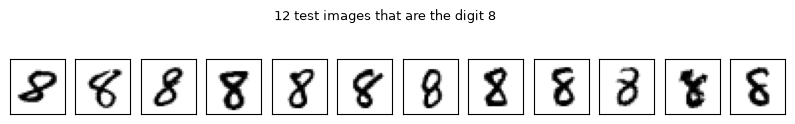

In [149]:
from sklearn.model_selection import train_test_split

d = 8                         # your digit
DATA = np.load("mnist.npz")            # see Project 2 for where to get it
x_train = DATA["x_train"].reshape(len(DATA["x_train"]), -1) / 255.0
x_test = DATA["x_test"].reshape(len(DATA["x_test"]), -1) / 255.0
y_train = (DATA["y_train"] == d).astype(int)
y_test = (DATA["y_test"] == d).astype(int)

print(np.shape(x_train))
print(np.shape(x_test))

print(np.shape(DATA["x_train"]))


# print(f"train {len(y_train)}, test {len(y_test)} images")
# print(f"fraction of eights: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
# print(f"accuracy of 'never an eight' on the test set: {1 - y_test.mean():.4f}")

# WE plot a selection of the data points for fun!!
number_of_handwritten_figures_to_be_displayed = 12
fig, ax = plt.subplots(1, number_of_handwritten_figures_to_be_displayed , figsize=(10, 1.6))
for a, i in zip(ax, np.where(y_test == 1)[0][:number_of_handwritten_figures_to_be_displayed ]):
    a.imshow(x_test[i].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
fig.suptitle(f"{number_of_handwritten_figures_to_be_displayed} test images that are the digit {d}", fontsize=9)
plt.show()


In [150]:
t0 = time.time()
layers = create_layers_batch(784, [100, 2])
# layers, hist = train(x_train, one_hot(y_train, 10), layers, "relu", head="mse", gamma=0.1, epochs=20,
#                      batch_size = 100, X_test = x_test, y_test = y_test)
layers, hist = train(x_train, one_hot(y_train, 2), layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size = 100, rng=None, X_test = x_test, y_test = y_test)
print(f"test accuracy after 20 epochs: {hist['test_accuracy'][-1]:.2%}  ({time.time() - t0:.0f} s)")

test accuracy after 20 epochs: 96.16%  (32 s)


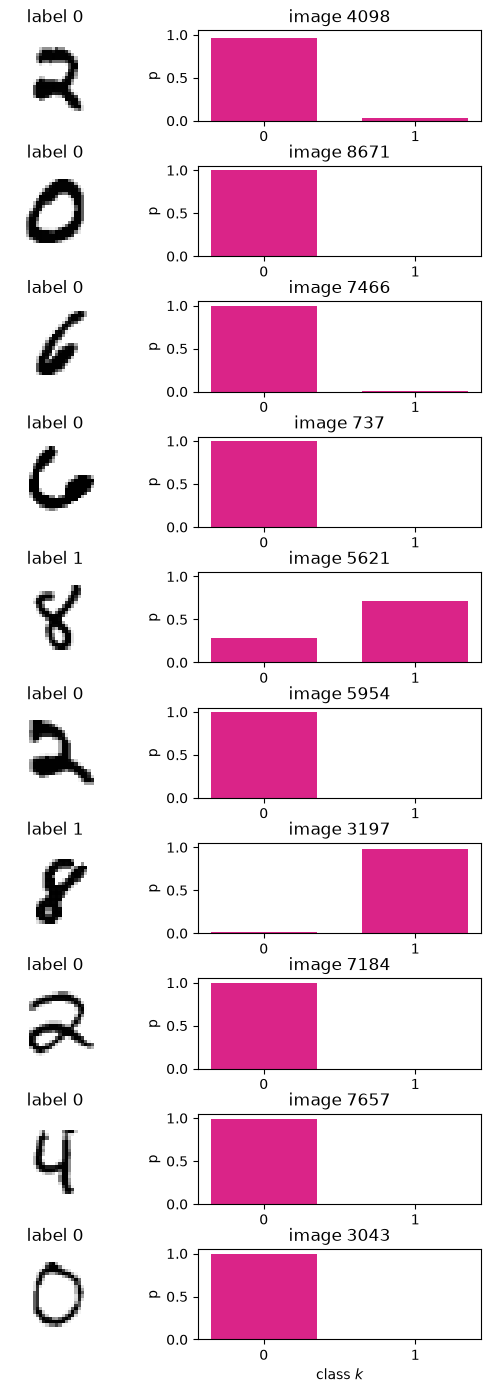

image 4098 (label 0): delta^L = a - y = [-0.  0.]
image 8671 (label 0): delta^L = a - y = [-0.001  0.001]
image 7466 (label 0): delta^L = a - y = [-0.  0.]
image 737 (label 0): delta^L = a - y = [-0.002  0.002]
image 5621 (label 1): delta^L = a - y = [-0.001  0.001]
image 5954 (label 0): delta^L = a - y = [-0.005  0.005]
image 3197 (label 1): delta^L = a - y = [-0.289  0.292]
image 7184 (label 0): delta^L = a - y = [-0.005  0.005]
image 7657 (label 0): delta^L = a - y = [-0.  0.]
image 3043 (label 0): delta^L = a - y = [-0.036  0.037]


In [151]:
P = predict(x_test, layers, "relu", "softmax")
pred, pmax = P.argmax(axis=1), P.max(axis=1)
# i_A = int(np.argmax(np.where(pred == y_test, pmax, -1)))     # the most confident correct prediction
# i_B = int(np.argmin(pmax))                                   # the least confident prediction

k = np.random.choice(len(x_test), size=10, replace=False)

number_of_images = 10

RED = "#DA2488"

fig = plt.figure(figsize=(6.2, 1.7 * number_of_images))
gs = fig.add_gridspec(number_of_images, 2, width_ratios=[1, 2.6], wspace=0.45, hspace=0.5)
for row, i in enumerate((k)):
    axi = fig.add_subplot(gs[row, 0])
    axi.imshow(x_test[i].reshape(28, 28), cmap="gray_r")
    axi.set_title(f"label {y_test[i]}")
    axi.axis("off")
    axi.set_xticks([])
    axi.set_yticks([])
    axb = fig.add_subplot(gs[row, 1])
    axb.bar(np.arange(2), P[i], color=RED, width=0.7)
    axb.set_xticks(np.arange(2))
    axb.set_ylim(0, 1.05)
    axb.set_ylabel("p")
    axb.set_title(f"image {i}")
axb.set_xlabel("class $k$")
plt.show(fig, "mnist_question.png")

alphabet = ["A", "B", "C", "D", "E", "F", "G", "H", "I","K"]

for row, i in enumerate((k)):
    delta = P[row] - one_hot(y_test[row:row + 1], 2)[0]
    print(f"image {i} (label {y_test[i]}): delta^L = a - y = {np.round(delta, 3)}")

# y_B = one_hot(y_test[i_B:i_B + 1], 2)[0]
# delta_B = P[i_B] - y_B
# print(f"\nimage B: label {y_test[i_B]},  one-hot y = {y_B.astype(int)}")
# for k in np.argsort(-np.abs(delta_B)):                       # largest |delta_k| first
#     print(f"  delta_{k} = a_{k} - y_{k} = {P[i_B, k]:.2f} - {y_B[k]:.0f} = {delta_B[k]:+.2f}")

In [152]:
from sklearn.linear_model import LogisticRegression
# Initialize the model (multinomial logistic regression with the saga solver)
model = LogisticRegression(solver='saga', max_iter=1000, random_state=42)
# Train the model
model.fit(x_train, y_train)
from sklearn.metrics import accuracy_score
# Make predictions on the test set
y_pred = model.predict(x_test)
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

Model Accuracy: 0.9613


**b)** Train logistic regression (no hidden layer, sigmoid output, cross
entropy) and a network with one hidden layer on the training set, with the
SGD of Project 2. On the test set, at threshold $0.5$, report for both the
confusion matrix in the layout of Eq. (5.67) and the accuracy, precision,
recall and $F_1$ from your own exercise-1 functions, checked against the
`scikit-learn` template. Say in two sentences what the matrices tell you
that the two accuracies do not, and what fraction of the remaining error
(relative to the majority rule) each classifier removed.



In [ ]:
def make_batches(n, batch_size, rng):
    """Shuffle the indices and split them into minibatches."""
    idx = rng.permutation(n)
    return [idx[i:i + batch_size] for i in range(0, n, batch_size)]

def optimiser_step(method, param, g, state, t, gamma, beta=0.9, rho=0.99,
                beta1=0.9, beta2=0.999, eps=1e-6):
    """One update of param from the gradient g at step t (t = 1, 2, ...), Eqs. (4.10), (4.28),
    (4.42)-(4.45), (4.47)-(4.48) and (4.51)-(4.55).  state carries the running quantities."""
    if method == "plain":
        return param - gamma * g, state
    if method == "momentum":
        v = beta * state.get("v", 0.0) + gamma * g               # Eq. (4.28)
        state["v"] = v
        return param - v, state
    if method == "adagrad":
        r = state.get("r", 0.0) + g * g                           # Eq. (4.42)
        state["r"] = r
        return param - gamma * g / (np.sqrt(r) + eps), state      # Eq. (4.45)
    if method == "rmsprop":
        r = rho * state.get("r", 0.0) + (1.0 - rho) * g * g       # Eq. (4.47)
        state["r"] = r
        return param - gamma * g / (np.sqrt(r) + eps), state      # Eq. (4.48)
    if method == "adam":
        m = beta1 * state.get("m", 0.0) + (1.0 - beta1) * g       # Eq. (4.51)
        r = beta2 * state.get("r", 0.0) + (1.0 - beta2) * g * g   # Eq. (4.52)
        state["m"], state["r"] = m, r
        m_hat = m / (1.0 - beta1**t)                              # Eq. (4.54)
        r_hat = r / (1.0 - beta2**t)
        return param - gamma * m_hat / (np.sqrt(r_hat) + eps), state   # Eq. (4.55)
    raise ValueError(f"unknown method {method}")


def step_length(t, t0, t1):
    """The schedule of Eq. (4.40)."""
    return t0 / (t + t1)

def mse(predict, target):
    print("target", np.shape(target))
    # print("predict", np.shape(predict))
    print(predict)
    return jnp.mean((target-predict)**2)

def jax_cost(input, layers, activation_funcs, target):
    """
        LLM tag: AI was used here to help me debug some problems with inhomogenous shapes. 
        The problem was that I had mixed the "cost" function and this jax_cost function, and when the LLM
        reminded me to not mix them (e.g. by renaming this jax_cost function), my code worked. 
        """
    _, activations = feed_forward_batch(input, layers, activation_funcs)
    prediction = activations[-1]
    return mse(prediction, target)

gradient_func = jax.grad(cost, argnums=1)

# def train_network_stochastic_gradient(inputs, targets, layers, activation_funcs, schedule = None, gamma=0.01, epochs=100, method="plain", batch_size=5, tol=1e-6, seed=2026):
#     """
#     LLM tag:
#     When we had our own suggestion for how to combine the functions, we checked with the LLMs if they agreed, especially with the 
#     placement of the epochs loop, and updates of t. We also got the convergence check from ChatGPT.
#     """
#     # Independent optimizer states for each weight and bias
#     states = [({"W": {}, "b": {}}, {"W": {}, "b": {}}) for W, b in layers]
#     history = []
#     t = 0
#     for epoch in range(epochs):
#         # Calculate gradients for the whole network
#         for batch in make_batches(len(inputs), batch_size, rng):
#             t += 1
#             layers_grad = gradient_func(inputs[batch], layers, activation_funcs, targets[batch])
#             gamma_t = gamma if schedule is None else step_length(t, *schedule)    
        
#             new_layers = []
#             new_states = []

#             # Update each layer's weights and biases
#             for (W, b), (dW, db), (state_W, state_b) in zip(layers, layers_grad, states):
#                 W, state_W = optimiser_step(method, W, dW, state_W,epoch + 1, gamma_t)
#                 b, state_b = optimiser_step(method, b, db, state_b,epoch + 1, gamma_t)
#                 new_layers.append((W, b))
#                 new_states.append((state_W, state_b))
#             layers = new_layers
#             states = new_states

#         # Record training progress
#         if epoch % 50 == 0 or epoch == epochs - 1: #find out what this does
#             predictions = feed_forward_batch(inputs, layers, activation_funcs)
#             c = cost(inputs, layers, activation_funcs, targets)
#             # acc = accuracy(predictions, targets)
#             history.append((epoch, float(c), mse(predictions, targets)))

#             if c < tol:
#                 print(f"Converged at epoch {epoch}: cost = {c:.6g}")
#                 # break


#     return layers, history, predictions

def train_stochastic(X, Y, layers, method, schedule, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """
    LLM tag: I got some help from the UiO GPT to debug this function. It reminded me to update the layers and states 
    with the new layers and states, as well as the "idx" and using it in "layers grad", to make sure i actually use
    the mini batches. 
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    states = []
    t = 0
    for _ in layers:
        states.append(({},{}))
    for epoch in tqdm(range(epochs), desc="Training", unit="epoch"):
        order = rng.permutation(n)

        for s in range(0, n, M):
            t += 1
            gamma_t = gamma if schedule is None else step_length(t, *schedule)

            idx = order[s:s + M]

            # Use the actual minibatch
            layers_grad = backpropagation(
                X[idx], Y[idx], layers, hidden_activation, head="mse"
            )

            new_layers = []
            new_states = []

            for (W, b), (dW, db), (state_W, state_b) in zip(
                layers, layers_grad, states
            ):
                W, state_W = optimiser_step(
                    method, W, dW, state_W, t, gamma_t
                )
                b, state_b = optimiser_step(
                    method, b, db, state_b, t, gamma_t
                )

                new_layers.append((W, b))
                new_states.append((state_W, state_b))

            layers = new_layers
            states = new_states

        history["cost"].append(
            cost(X, Y, layers, hidden_activation)
        )


    if X_test is not None:
        P_test = predict(X_test, layers, hidden_activation, head)
        pred_test = np.argmax(P_test, axis=1)
        history["test_accuracy"].append(np.mean(pred_test == y_test))

    return layers, history

(60000, 784)
(10000, 784)
(60000, 28, 28)
train 60000, test 10000 images
fraction of eights: train 0.098, test 0.097
accuracy of 'never an eight' on the test set: 0.9026


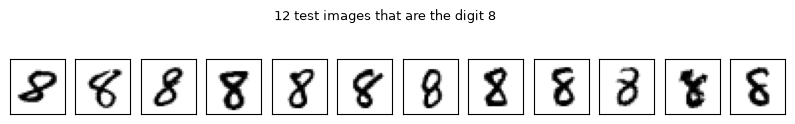

In [183]:

d = 8                         # your digit
DATA = np.load("mnist.npz")            # see Project 2 for where to get it
x_train = DATA["x_train"].reshape(len(DATA["x_train"]), -1) / 255.0
x_test = DATA["x_test"].reshape(len(DATA["x_test"]), -1) / 255.0
y_train = (DATA["y_train"] == d).astype(int)
y_test = (DATA["y_test"] == d).astype(int)

print(np.shape(x_train))
print(np.shape(x_test))

print(np.shape(DATA["x_train"]))


print(f"train {len(y_train)}, test {len(y_test)} images")
print(f"fraction of eights: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
print(f"accuracy of 'never an eight' on the test set: {1 - y_test.mean():.4f}")

# WE plot a selection of the data points for fun!!
number_of_handwritten_figures_to_be_displayed = 12
fig, ax = plt.subplots(1, number_of_handwritten_figures_to_be_displayed , figsize=(10, 1.6))
for a, i in zip(ax, np.where(y_test == 1)[0][:number_of_handwritten_figures_to_be_displayed ]):
    a.imshow(x_test[i].reshape(28, 28), cmap="gray_r"); a.set_xticks([]); a.set_yticks([])
fig.suptitle(f"{number_of_handwritten_figures_to_be_displayed} test images that are the digit {d}", fontsize=9)
plt.show()

In [184]:
print(np.shape(x_train))
print(np.shape(y_train))

# x_train = x_train[:100,:]
print(np.shape(x_train))

(60000, 784)
(60000,)
(60000, 784)


In [185]:
# import time
# from tqdm.auto import tqdm

# t0 = time.time()
# layers = create_layers_batch(784, [100, 2])

# print("X:", x_train.shape)
# print("Y:", one_hot(y_train, 2).shape)
# print("X_test:", x_test.shape)
# print("y_test:", y_test.shape)

# layers_stochastic, hist_stochastic, = train_stochastic(x_train, one_hot(y_train,2), layers, "adam", schedule = None, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
#           batch_size = 5, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=x_test, y_test=y_test, verbose=False)

# print(f"test accuracy after 20 epochs: {hist['test_accuracy'][-1]:.2%}  ({time.time() - t0:.0f} s)")

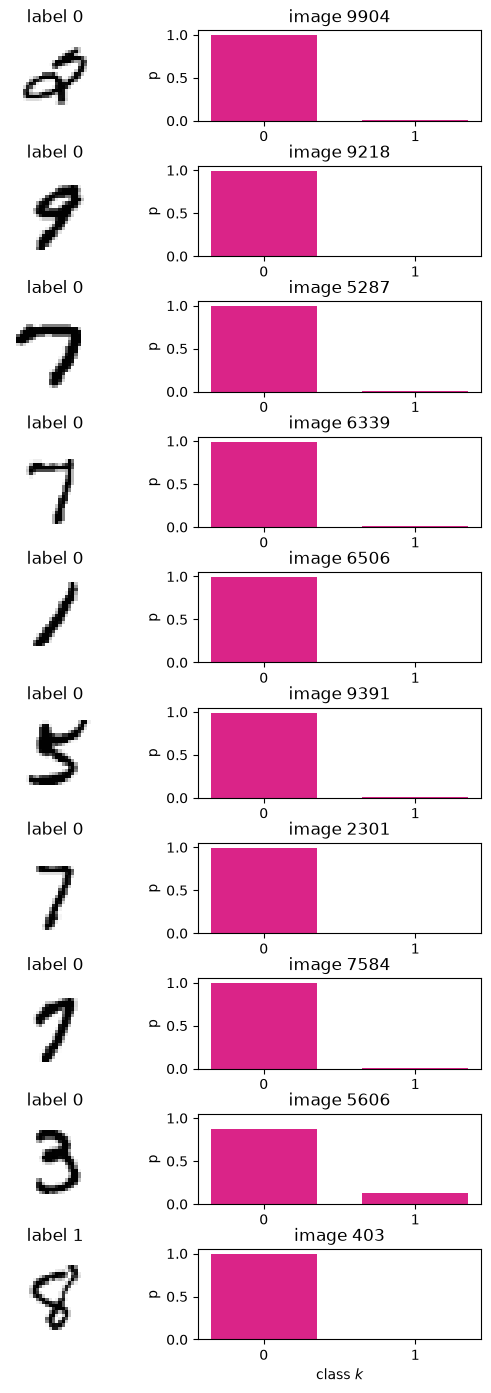

image 9904 (label 0): delta^L = a - y = [-0.008  0.008]
image 9218 (label 0): delta^L = a - y = [-0.008  0.008]
image 5287 (label 0): delta^L = a - y = [-0.008  0.008]
image 6339 (label 0): delta^L = a - y = [-0.008  0.008]
image 6506 (label 0): delta^L = a - y = [-0.008  0.008]
image 9391 (label 0): delta^L = a - y = [-0.008  0.008]
image 2301 (label 0): delta^L = a - y = [-0.127  0.127]
image 7584 (label 0): delta^L = a - y = [-0.008  0.008]
image 5606 (label 0): delta^L = a - y = [-0.008  0.008]
image 403 (label 1): delta^L = a - y = [-0.008  0.008]
[[0.99207262 0.00792738]
 [0.99207262 0.00792738]
 [0.99207262 0.00792738]
 ...
 [0.99207262 0.00792738]
 [0.63326945 0.36673055]
 [0.99207262 0.00792738]]


In [186]:
P = predict(x_test, layers, "relu", "softmax")
pred, pmax = P.argmax(axis=1), P.max(axis=1)
# i_A = int(np.argmax(np.where(pred == y_test, pmax, -1)))     # the most confident correct prediction
# i_B = int(np.argmin(pmax))                                   # the least confident prediction

k = np.random.choice(len(x_test), size=10, replace=False)

number_of_images = 10

RED = "#DA2488"

fig = plt.figure(figsize=(6.2, 1.7 * number_of_images))
gs = fig.add_gridspec(number_of_images, 2, width_ratios=[1, 2.6], wspace=0.45, hspace=0.5)
for row, i in enumerate((k)):
    axi = fig.add_subplot(gs[row, 0])
    axi.imshow(x_test[i].reshape(28, 28), cmap="gray_r")
    axi.set_title(f"label {y_test[i]}")
    axi.axis("off")
    axi.set_xticks([])
    axi.set_yticks([])
    axb = fig.add_subplot(gs[row, 1])
    axb.bar(np.arange(2), P[i], color=RED, width=0.7)
    axb.set_xticks(np.arange(2))
    axb.set_ylim(0, 1.05)
    axb.set_ylabel("p")
    axb.set_title(f"image {i}")
axb.set_xlabel("class $k$")
plt.show(fig, "mnist_question.png")

alphabet = ["A", "B", "C", "D", "E", "F", "G", "H", "I","K"]

for row, i in enumerate((k)):
    delta = P[row] - one_hot(y_test[row:row + 1], 2)[0]
    print(f"image {i} (label {y_test[i]}): delta^L = a - y = {np.round(delta, 3)}")

# y_B = one_hot(y_test[i_B:i_B + 1], 2)[0]
# delta_B = P[i_B] - y_B
# print(f"\nimage B: label {y_test[i_B]},  one-hot y = {y_B.astype(int)}")
# for k in np.argsort(-np.abs(delta_B)):                       # largest |delta_k| first
#     print(f"  delta_{k} = a_{k} - y_{k} = {P[i_B, k]:.2f} - {y_B[k]:.0f} = {delta_B[k]:+.2f}")

print(P)

[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.87258879 0.12741121]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.97444848 0.02555152]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99387207 0.00612793]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00792738]
[0.99207262 0.00

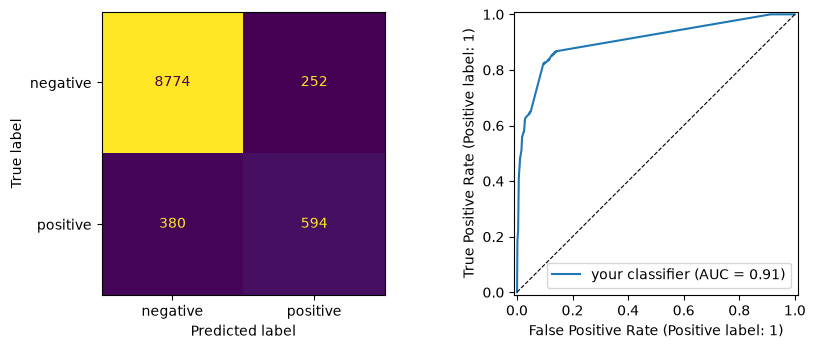

In [201]:
p_test = np.asarray(P[:,1]).ravel()
y_pred = p_test > 0.5

for each in P:
    print(each)

print(np.shape(y_pred))
print(np.shape(y_test))


cm = sk_confusion_matrix(y_test, y_pred)   # [[TN, FP], [FN, TP]]

print(cm)
print(f"accuracy {accuracy_score(y_test, y_pred):.4f}  precision {precision_score(y_test, y_pred, zero_division=0):.4f}  "
      f"recall {recall_score(y_test, y_pred):.4f}  F1 {f1_score(y_test, y_pred):.4f}")
print(sk_classification_report(y_test, y_pred, target_names=["negative", "positive"], zero_division=0))

fpr, tpr, thresholds = sk_roc_curve(y_test, p_test, drop_intermediate=False)
print(f"AUC {roc_auc_score(y_test, p_test):.4f}")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
ConfusionMatrixDisplay(cm, display_labels=["negative", "positive"]).plot(ax=ax[0], colorbar = False)
RocCurveDisplay.from_predictions(y_test, p_test, ax=ax[1], name="your classifier")
ax[1].plot([0, 1], [0, 1], "k--", lw=0.8)
plt.tight_layout(); plt.show()

**c)** The ROC curves of both classifiers in one figure, with the AUC by
your trapezoidal rule, by your rank formula and by `roc_auc_score`, and the
point corresponding to $t=0.5$ marked on each curve. Add a histogram of the
output probabilities of the test images, separately for the two classes,
on a logarithmic vertical axis. Where do the errors live, and what does the
difference between the two AUCs say that the confusion matrices at $0.5$ do
not?



**d)** Standard errors: of the test accuracy and of the recall (Eq. 2.24,
$\sqrt{\hat p(1-\hat p)/n}$ with the appropriate $n$ in each case). Would
you call the difference between your two classifiers significant?

## Exercise 3 (optional): ten classes — the matrix Project 2 asks for

**a)** Train your softmax network (or `scikit-learn`'s `MLPClassifier`, or
the week-41 `[784, 100, 10]` network) on the MNIST training set and build
the $10\times10$ confusion matrix of the test set by hand ($C_{ij}$ = number
of test images of true class $i$ predicted as class $j$; `np.add.at` does it
in one line). Check it against `sklearn.metrics.confusion_matrix`.

**b)** From the matrix: the per-class precision (columns) and recall (rows),
checked against `sklearn.metrics.classification_report`; the five most
frequent confusions (true $\to$ predicted); the $2\times2$ matrix of your
digit $d$ against the rest, read off the big matrix. Compare the latter with
the binary classifiers of exercise 2: same model? same decision rule? which
is better, and why?

**c)** Plot the matrix as an image with the diagonal removed, annotated with
the counts, and the per-class precision and recall as bars. Which pairs of
digits are confused in *both* directions, and which only in one? Look at a
few of the confused images and say whether you would have got them right.

**d)** The test accuracy comes with the standard error of Eq. (2.24). Train
a second network with a different architecture or a different seed and
report both accuracies with their error bars. Is the difference
significant? How many test images would you need to resolve a difference of
$0.1$ percentage points at $97\%$ accuracy?

In [ ]:
...

Ellipsis

## Insights you should have gained this week — a self-check

Before you hand in, go through the list below without looking at the notes.
Each row is a question we may ask in the Tuesday session or on Project 2;
the right-hand column is the insight it tests, in one sentence.

| Ask yourself | The insight it tests |
|---|---|
| A classifier scores $97\%$ accuracy. Is it good? | Not knowable without the majority-class accuracy: on a problem with $9\%$ positives, $91\%$ is free, and the honest number is the fraction of the *remaining* error removed. Accuracy is $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$, blind to the rare class. |
| What are the four numbers everything else is made of? | TP, FN, FP, TN — the confusion matrix (Eq. 5.67), rows true and columns predicted; the two off-diagonal entries are two *different* errors with different costs. |
| Precision or recall — which one do I want? | A question about the application, not the model: screening wants recall (few misses), a spam filter wants precision (few false alarms); the threshold trades one for the other. |
| Why the harmonic mean in $F_1$? | It is small unless *both* precision and recall are large ($F_1\le2\min$); the arithmetic mean would reward a classifier that is perfect on one and useless on the other. |
| What does an AUC of $0.99$ mean? | Pick a random positive and a random negative: with probability $0.99$ the positive gets the higher score. It depends on the ranking alone — not on the threshold, not on the class balance. |
| The threshold moved from $0.5$ to $0.1$. What changed? | Only the operating point: weights, probabilities, ranking, ROC curve and AUC are identical; every number computed from the four counts changed, and accuracy can fall while recall rises. |
| Why is the ROC curve blind to class imbalance and the PR curve not? | TPR and FPR are each normalised within one class; precision has FP in its denominator, so the proportion of positives enters it — the PR floor is the prevalence. |
| What does the MCC add to precision and recall? | It is the correlation between labels and decisions, uses all four counts, is symmetric in the classes, and is $0$ for the majority rule — the one scalar that is hard to fool by imbalance. |
| Rows or columns of the $10\times10$ matrix? | Rows are the truth: a row over its sum is the recall of that class; columns are the decisions: a column over its sum is its precision. |
| How accurate is an accuracy? | It is a binomial proportion: standard error $\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24) — $\pm0.15\%$ on $10\,000$ images, $\pm1.7\%$ on $143$; differences inside the error bar are not differences. |
| Why do we train on the cross entropy and report accuracy? | Accuracy is a step function of the parameters with zero gradient; the cross entropy is a smooth surrogate minimised in roughly the same place — a lower cross entropy does not guarantee a higher accuracy. |

### Practicalities

Deliver your solutions (a single Jupyter notebook) in Canvas before
**Friday October 23 at midnight**. Collaboration is encouraged — list your
collaborators. The functions you write this week are the ones you will use
in part e) of Project 2 (deadline November 6); the solutions to the
exercises of weeks 41 and 42 are in the weekly material folders of the
course repository. Validation sets and cross-validation for your Project 2
network are the topic of week 44.

**Declaration of the use of large language models (LLMs).** Many of you use
ChatGPT, Claude, Copilot or similar tools when solving the weekly exercises,
and that is fine — but it has to be declared, for the weekly exercises as
well as for the projects. Add a short paragraph at the end of your notebook
(the cell below is a template) stating which tools you used and for what
(code, debugging, explanations, text), or that you did not use any. A few
sentences are enough; the full guidelines, which you must follow in the
project reports, are at
[LLM_Usage_Declaration_Guidelines.md](https://github.com/EducationalMaterialUiO/MachineLearningUiO/blob/main/LLM_Usage_Declaration_Guidelines.md). Remember that *you* are
responsible for every line you hand in: be prepared to explain it.

## Declaration of the use of LLMs

*(Replace this text with your own declaration, or write "No LLMs were used".)*

Tools used: … (for example ChatGPT, Claude, GitHub Copilot)

What they were used for: … (for example debugging the sorted pass in
exercise 1, explaining the rank formula in exercise 1c, polishing this text)

What was done without them: …